# ¿Qué temas preocupan a los españoles?
Análisis y gráficos de Caesius a partir de las tabulaciones del CIS de 2026.

**Para ejecutar:** guarda este notebook en la raíz del proyecto, junto a `datos_limpios`, y selecciona el kernel de `.venv`. Ejecuta la instalación una vez y después las celdas en orden.

Las imágenes definitivas se crean en `imagenes_definitivas`: **PNG a 300 ppp y SVG vectorial**, con fondo blanco, fuente y notas incluidas. También se guarda el CSV de cada gráfico. Ejecutar otra vez sustituye estos resultados; no modifica los datos originales. No hace falta capturar la pantalla.

Los gráficos representan porcentajes ponderados de personas que mencionan cada tema entre hasta tres respuestas. No son porcentajes de todas las menciones ni deben sumar 100 %. Los títulos se refieren al conjunto de la muestra; el análisis por edad corresponde a problemas personales. El artículo se centra en los resultados, sin referencias personales de la autora.


In [1]:
%pip install "pandas>=2.2,<4" "numpy>=1.26" "matplotlib>=3.8,<4" "wordcloud>=1.9,<2"

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [2]:
from pathlib import Path
import json, html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import textwrap
from IPython.display import display, HTML

# Busca el proyecto tanto desde la raíz como desde datos_limpios.
BASE = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "datos_limpios" / "preocupaciones_total.csv").is_file()), None)
if BASE is None:
    raise FileNotFoundError("Abre el notebook en el proyecto que contiene datos_limpios/preocupaciones_total.csv")
MES = "2026-10"  # El artículo adjunto corresponde a este mes.
SALIDA = BASE / "imagenes_definitivas"
SALIDA.mkdir(parents=True, exist_ok=True)
datos = pd.read_csv(BASE / "datos_limpios" / "preocupaciones_total.csv",
                    sep=";", decimal=",", encoding="utf-8-sig", dtype={"estudio": str})
claves = ["mes", "tipo_problema", "dimension", "grupo", "problema"]
assert not datos.duplicated(claves).any(), "Hay registros duplicados: revisa el preprocesado."
assert datos.porcentaje.dropna().between(0, 100).all()
assert MES in set(datos.mes)
assert datos.orden_mencion.eq("total").all(), "Se esperan menciones totales, no primeras respuestas."
es_tema = datos.es_tema.astype(str).str.lower().eq("true")
EXCLUIR = {"Ninguno", "Ninguna", "N.S.", "N.C.", "Otras respuestas"}
temas = datos[es_tema & ~datos.problema.isin(EXCLUIR)].copy()
nacional = temas[temas.dimension.eq("general") & temas.grupo.eq("TOTAL")].copy()
foto = nacional[nacional.mes.eq(MES)].copy()
pais = foto[foto.tipo_problema.eq("espana")].set_index("problema").porcentaje
personal = foto[foto.tipo_problema.eq("personal")].set_index("problema").porcentaje
EDADES = ["De 18 a 24 años", "De 25 a 34 años", "De 35 a 44 años", "De 45 a 54 años",
          "De 55 a 64 años", "De 65 a 74 años", "75 y más años"]
EDAD_CORTA = ["18–24", "25–34", "35–44", "45–54", "55–64", "65–74", "75+"]
VIVIENDA = "La vivienda"
ECONOMIA = "La crisis económica, los problemas de índole económica"
EMPLEO = "Los problemas relacionados con la calidad del empleo"
SANIDAD = "La sanidad"
NOMBRES = {VIVIENDA:"Vivienda", ECONOMIA:"Problemas económicos", EMPLEO:"Calidad del empleo",
           SANIDAD:"Sanidad", "La inmigración":"Inmigración", "El paro":"Paro", "La educación":"Educación",
           "El Gobierno y partidos o políticos/as concretos/as":"Gobierno y políticos concretos",
           "Los problemas políticos en general":"Problemas políticos en general",
           "El mal comportamiento de los/as políticos/as":"Comportamiento de los políticos"}
VERDE, CORAL, TINTA, GRIS = "#146B55", "#D15A3F", "#172C29", "#687B75"
FUENTE = "Origen de los datos: Centro de Investigaciones Sociológicas."
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":11,
    "axes.spines.top":False,"axes.spines.right":False,"axes.spines.left":False,
    "axes.edgecolor":"#B6C3BB","axes.labelcolor":TINTA,"text.color":TINTA,
    "xtick.color":GRIS,"ytick.color":TINTA,"svg.fonttype":"none",
    "figure.facecolor":"white","axes.facecolor":"white"})
def fmt(x): return f"{x:.1f}".replace(".", ",")
def envolver(p): return textwrap.fill(NOMBRES.get(p,p), 29)
def cabecera(fig,titulo,subtitulo):
    fig.text(.035,.965,"CAESIUS  /  SOCIEDAD",fontsize=10,color=VERDE,weight="bold",va="top")
    fig.text(.035,.92,titulo,fontsize=21,color=TINTA,weight="bold",va="top")
    fig.text(.035,.86,subtitulo,fontsize=11,color=GRIS,va="top")
def pie(fig,temporal=False,extra=""):
    periodo = "Barómetros enero–octubre de 2026, sin agosto." if temporal else "Barómetro de octubre de 2026, estudio 3582."
    fig.text(.035,.066,FUENTE,fontsize=9,color=GRIS)
    fig.text(.035,.043,periodo+" Elaboración: Caesius.",fontsize=9,color=GRIS)
    fig.text(.035,.02,extra or "Hasta tres menciones por persona; los porcentajes de los temas no suman 100 %.",fontsize=8.5,color=GRIS)
def guardar(fig,nombre,tabla):
    fig.savefig(SALIDA/f"{nombre}.png",dpi=300,facecolor="white")
    fig.savefig(SALIDA/f"{nombre}.svg",facecolor="white")
    tabla.to_csv(SALIDA/f"{nombre}.csv",sep=";",decimal=",",index=False,encoding="utf-8-sig")
    plt.show()
    plt.close(fig)
    print(f"Guardados: {nombre}.png / .svg / .csv")
print(f"{datos.mes.nunique()} meses disponibles. Mes analizado: {MES}.")
print(f"Salida: {SALIDA}")


9 meses disponibles. Mes analizado: 2026-10.
Salida: c:\Users\byana\Desktop\PROYECTOS CAESIUS\PREOCUPACIONES_ESPAÑOLES\imagenes_definitivas


## 1 · Una preocupación muy por delante del resto
**Qué muestra:** los diez temas más mencionados como problemas de España, en octubre. El porcentaje se refiere a personas que mencionan cada tema, no a su proporción dentro de todas las respuestas.

**Lectura para el artículo:** la vivienda ocupa una posición claramente destacada. La calidad del empleo y el paro son categorías distintas; no basta con este gráfico para medir las condiciones laborales. El orden entre porcentajes próximos es descriptivo.

**Diseño:** barras horizontales ordenadas y una sola categoría destacada. No hace falta una leyenda de colores: todas las barras representan la misma variable. El CSV conserva la denominación original.

### Texto del artículo

La distancia entre la vivienda y el siguiente tema es de casi 35 puntos porcentuales. También llama la atención la diferencia dentro de las preocupaciones laborales: la calidad del empleo se menciona aproximadamente el doble que el paro (9,6 %). Son categorías distintas: este ranking recoge lo que la gente menciona, no mide directamente la precariedad ni el desempleo.

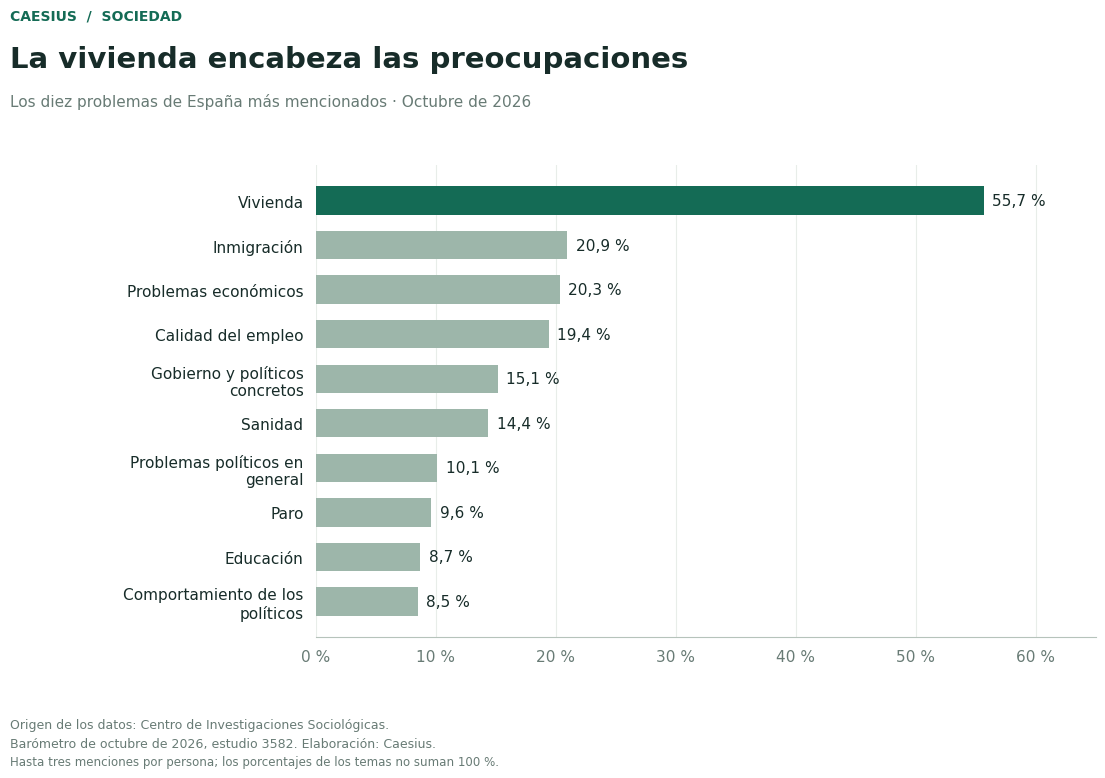

Guardados: 01-ranking.png / .svg / .csv


In [3]:
ranking = pais.nlargest(10).sort_values().rename("porcentaje").reset_index()
fig,ax=plt.subplots(figsize=(12,8))
fig.subplots_adjust(left=.29,right=.94,bottom=.18,top=.77)
ax.barh(range(len(ranking)),ranking.porcentaje,height=.64,
        color=[VERDE if p==VIVIENDA else "#9DB6AA" for p in ranking.problema])
ax.set_yticks(range(len(ranking)),[envolver(p) for p in ranking.problema])
ax.tick_params(axis="both",length=0,pad=9)
ax.set_xlim(0,65); ax.set_xticks(range(0,61,10))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f"{x:.0f} %"))
ax.xaxis.grid(True,color="#E8EDE9"); ax.set_axisbelow(True)
for i,v in enumerate(ranking.porcentaje):ax.text(v+.7,i,fmt(v)+" %",va="center",fontsize=11,color=TINTA)
cabecera(fig,"La vivienda encabeza las preocupaciones","Los diez problemas de España más mencionados · Octubre de 2026")
pie(fig)
guardar(fig,"01-ranking",ranking)

## 2 · Un salto en octubre, en dos preguntas distintas
**Qué muestra:** la vivienda como problema de España y como problema personal a lo largo del año. No se promedian meses ni se sustituyen los meses ausentes por cero.

**Lectura para el artículo:** comparar septiembre y octubre permite describir el salto, pero no explicarlo. Agosto interrumpe las líneas de forma expresa; el dato de septiembre no es una observación de agosto.

**Diseño:** dos colores estables para las dos preguntas, puntos en cada observación y etiquetas en el último mes. El eje parte de cero.

### Texto del artículo

Entre enero y julio, la vivienda como problema del país se mueve entre el 41,3 % y el 48,9 %. En septiembre baja al 37,5 % y en octubre alcanza el 55,7 %: **18,2 puntos más**, el máximo de los nueve barómetros analizados.

La preocupación personal por la vivienda también crece entre septiembre y octubre, del 27,9 % al 33,8 %, aunque el aumento es menor: 5,9 puntos. La serie permite describir ese salto; no demuestra qué lo provoca. Agosto queda como un hueco, sin interpolar un dato que no tenemos.

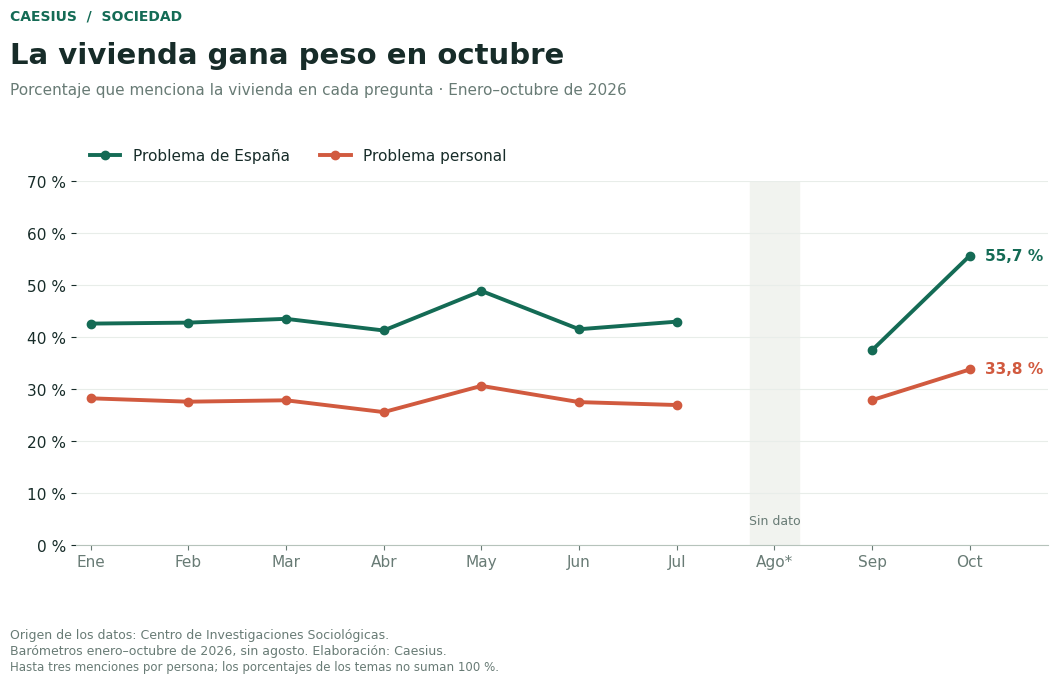

Guardados: 02-evolucion.png / .svg / .csv


In [4]:
serie = nacional[nacional.problema.eq(VIVIENDA)].pivot(index="mes",columns="tipo_problema",values="porcentaje")
calendario = pd.period_range(serie.index.min(),serie.index.max(),freq="M").astype(str)
serie=serie.reindex(calendario).rename_axis("mes")
fig,ax=plt.subplots(figsize=(12,7))
fig.subplots_adjust(left=.09,right=.90,bottom=.20,top=.72)
x=np.arange(len(serie))
for tipo,color,nombre in [("espana",VERDE,"Problema de España"),("personal",CORAL,"Problema personal")]:
    ax.plot(x,serie[tipo],color=color,lw=2.8,marker="o",ms=6,label=nombre)
    ax.text(x[-1]+.15,serie[tipo].iloc[-1],fmt(serie[tipo].iloc[-1])+" %",color=color,va="center",weight="bold")
ax.set_ylim(0,70); ax.set_xlim(-.15,9.8)
ax.set_xticks(x,["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago*","Sep","Oct"])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v,pos:f"{v:.0f} %"))
ax.yaxis.grid(True,color="#E8EDE9");ax.set_axisbelow(True)
ax.axvspan(6.75,7.25,color="#F1F3EF",zorder=0)
ax.text(7,4,"Sin dato",ha="center",fontsize=9,color=GRIS)
ax.legend(frameon=False,loc="lower left",bbox_to_anchor=(0,1.01),ncol=2)
cabecera(fig,"La vivienda gana peso en octubre","Porcentaje que menciona la vivienda en cada pregunta · Enero–octubre de 2026")
pie(fig,temporal=True)
guardar(fig,"02-evolucion",serie.reset_index())

## 3 · Lo colectivo y lo personal
**Qué muestra:** siete temas elegidos para comparar las dos preguntas, no un ranking completo. Cada línea une los dos porcentajes de un mismo tema. Verde identifica España y coral, lo personal; los colores se mantienen respecto al gráfico anterior.

**Lectura para el artículo:** economía y sanidad se mencionan más en lo personal. La diferencia no mide indiferencia, intensidad ni exposición real. Las tabulaciones no permiten reconstruir qué respondió una misma persona en ambas preguntas.

### Texto del artículo

La vivienda lidera ambas preguntas, pero aparece mucho más como problema de España (55,7 %) que como problema personal (33,8 %). Con la economía y la sanidad sucede lo contrario: **el 30,3 % cita los problemas económicos como propios y el 24,0 %, la sanidad**, frente al 20,3 % y el 14,4 % que los mencionan para el país.

Son dos preguntas con denominadores comparables, pero no intercambiables. Una persona puede reconocer un problema colectivo sin incluirlo entre los tres que más le afectan. Estas tablas no permiten saber quién da cada combinación de respuestas ni por qué.

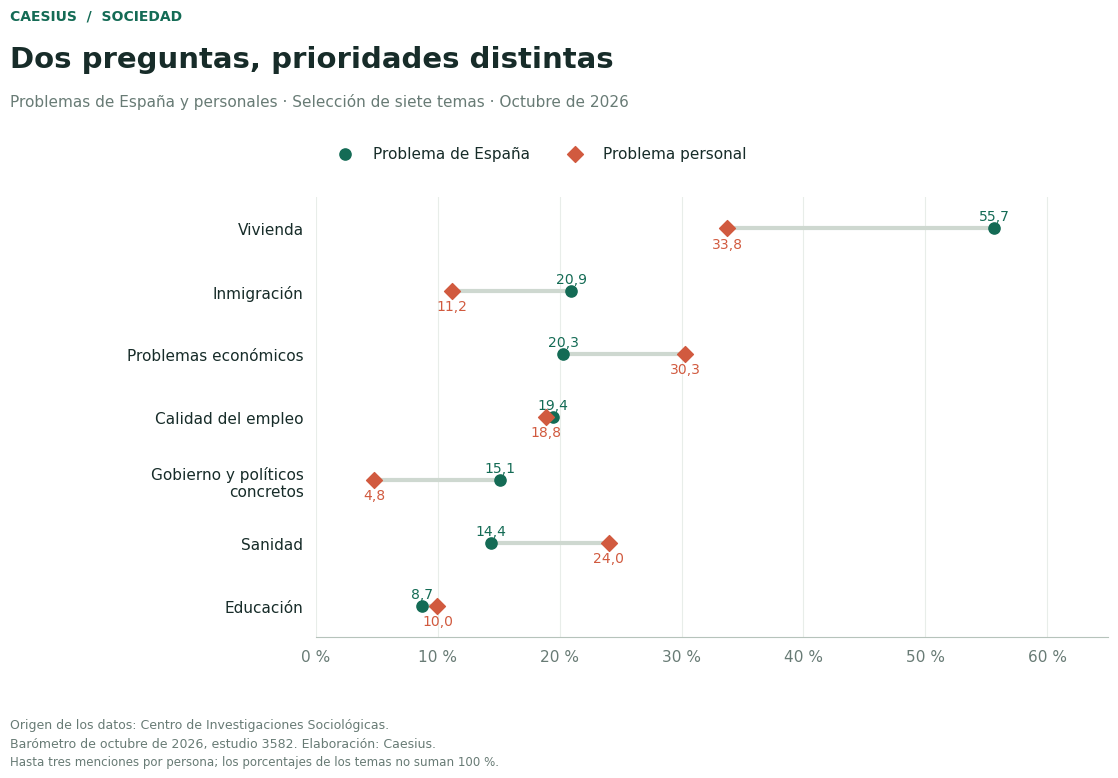

Guardados: 03-pais-personal.png / .svg / .csv


In [5]:
seleccion=[VIVIENDA,"La inmigración",ECONOMIA,EMPLEO,
           "El Gobierno y partidos o políticos/as concretos/as",SANIDAD,"La educación"]
comparacion=pd.DataFrame({"espana":pais.reindex(seleccion),"personal":personal.reindex(seleccion)})
assert comparacion.notna().all().all(),"Falta una categoría: no se sustituye por cero."
comparacion["diferencia_pp"]=comparacion.espana-comparacion.personal
fig,ax=plt.subplots(figsize=(12,8))
fig.subplots_adjust(left=.29,right=.95,bottom=.18,top=.73)
y=np.arange(len(comparacion))
ax.hlines(y,comparacion.espana,comparacion.personal,color="#CED8D0",lw=3)
for col,color,marker,label,dy in [("espana",VERDE,"o","Problema de España",-.19),
                                ("personal",CORAL,"D","Problema personal",.24)]:
    ax.scatter(comparacion[col],y,color=color,marker=marker,s=65,label=label,zorder=3)
    for i,v in enumerate(comparacion[col]):ax.text(v,i+dy,fmt(v),ha="center",va="center",color=color,fontsize=10)
ax.set_yticks(y,[envolver(p) for p in seleccion]);ax.invert_yaxis()
ax.set_ylim(len(y)-.5,-.5);ax.set_xlim(0,65)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v,pos:f"{v:.0f} %"))
ax.xaxis.grid(True,color="#E8EDE9");ax.set_axisbelow(True);ax.tick_params(length=0,pad=9)
ax.legend(frameon=False,loc="lower left",bbox_to_anchor=(0,1.05),ncol=2)
cabecera(fig,"Dos preguntas, prioridades distintas","Problemas de España y personales · Selección de siete temas · Octubre de 2026")
pie(fig)
guardar(fig,"03-pais-personal",comparacion.rename_axis("problema").reset_index())

## 4 · La edad cambia el mapa de los problemas personales
**Qué muestra:** cinco temas por siete grupos de edad, dentro de la pregunta de problemas personales. El mapa de calor usa una escala común de 0 a 70 % y muestra cada valor.

**Lectura para el artículo:** la vivienda destaca en los dos grupos más jóvenes. La economía alcanza su máximo entre 35 y 44 años y la calidad del empleo entre 25 y 34. Son diferencias entre grupos de una encuesta, no trayectorias de las mismas personas a lo largo de su vida.

**Límite:** no se dispone aquí de situación residencial ni de cruces conjuntos de edad con otras características; no se atribuyen causas ni efectos de generación. Los tamaños ponderados de cada grupo se incluyen en el CSV , pero no equivalen a recuentos de entrevistas sin ponderar.

### Texto del artículo

El contraste se hace más visible al mirar la edad. **El 65,0 % de quienes tienen entre 18 y 24 años menciona la vivienda como problema personal**, y también lo hace el 60,2 % del grupo de 25 a 34. Entre las personas de 75 o más años, el porcentaje es del 13,9 %.

Para los jóvenes, la vivienda aparece así como una preocupación especialmente cercana. Pero estos datos no dicen si quien responde alquila, intenta comprar o vive con su familia: vincular esa preocupación con la emancipación exigiría incorporar otras fuentes.

Las preocupaciones tampoco cambian todas de la misma manera. Los problemas económicos alcanzan su mayor porcentaje entre los 35 y los 44 años; la calidad del empleo, entre los 25 y los 34. La sanidad se menciona más en los grupos de mayor edad que entre los más jóvenes. Son diferencias entre edades en una encuesta concreta, no una prueba de que una generación vaya a mantener esas prioridades durante toda su vida.

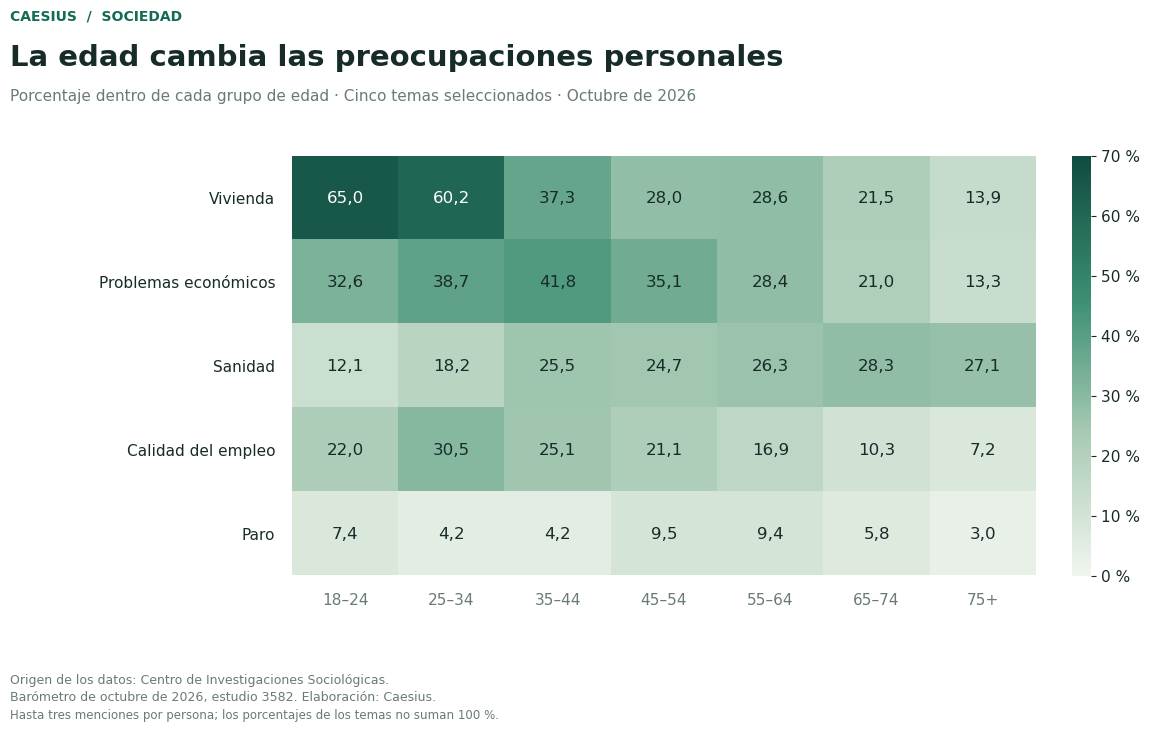

Guardados: 04-edad.png / .svg / .csv


In [6]:
edad=temas[temas.mes.eq(MES)&temas.tipo_problema.eq("personal")&temas.dimension.eq("Edad")&temas.grupo.isin(EDADES)].copy()
cuatro=[VIVIENDA,ECONOMIA,EMPLEO,SANIDAD]
cinco=[VIVIENDA,ECONOMIA,SANIDAD,EMPLEO,"El paro"]
tabla_edad=edad[edad.problema.isin(cinco)].pivot(index="problema",columns="grupo",values="porcentaje").reindex(index=cinco,columns=EDADES)
assert tabla_edad.notna().all().all(),"Hay una ausencia; no se sustituye por cero."
from matplotlib.colors import LinearSegmentedColormap
mapa=LinearSegmentedColormap.from_list("caesius",["#F1F5EE","#A9CBB5","#398D71","#104B40"])
fig,ax=plt.subplots(figsize=(12,7.5))
fig.subplots_adjust(left=.27,right=.89,bottom=.21,top=.77)
im=ax.imshow(tabla_edad.to_numpy(),cmap=mapa,vmin=0,vmax=70,aspect="auto")
ax.set_xticks(range(7),EDAD_CORTA);ax.set_yticks(range(5),[envolver(p) for p in cinco])
ax.tick_params(length=0,pad=12)
for i in range(5):
 for j in range(7):
  v=tabla_edad.iloc[i,j]
  ax.text(j,i,fmt(v),ha="center",va="center",color="white" if v>=43 else TINTA,fontsize=12)
for sp in ax.spines.values():sp.set_visible(False)
cax=fig.add_axes([.92,.21,.016,.56]);cb=fig.colorbar(im,cax=cax);cb.outline.set_visible(False)
cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v,pos:f"{v:.0f} %"))
cabecera(fig,"La edad cambia las preocupaciones personales","Porcentaje dentro de cada grupo de edad · Cinco temas seleccionados · Octubre de 2026")
pie(fig)
guardar(fig,"04-edad",edad[edad.problema.isin(cinco)][["problema","grupo","porcentaje","base_ponderada"]])

## Nube de temas · Recurso adicional
La nube conserva **categorías completas**, en lugar de contar palabras de las etiquetas. Su tamaño se pondera por el porcentaje nacional de octubre. No usa `cobertura_categorias.csv`: ese archivo informa de presencia de categorías, no de cuánta gente las menciona.

Se muestra como complemento visual; las barras permiten comparar valores con más precisión. No se incluye por defecto en el artículo para evitar repetir el primer gráfico. Se exporta a SVG y PNG al ejecutar esta celda.

Se guarda una nube de los 25 temas principales como PNG y SVG con atribución. Es un apoyo visual: las barras son más adecuadas para comparar cifras. Los temas completos son categorías codificadas por el CIS, no palabras literales de las personas entrevistadas.

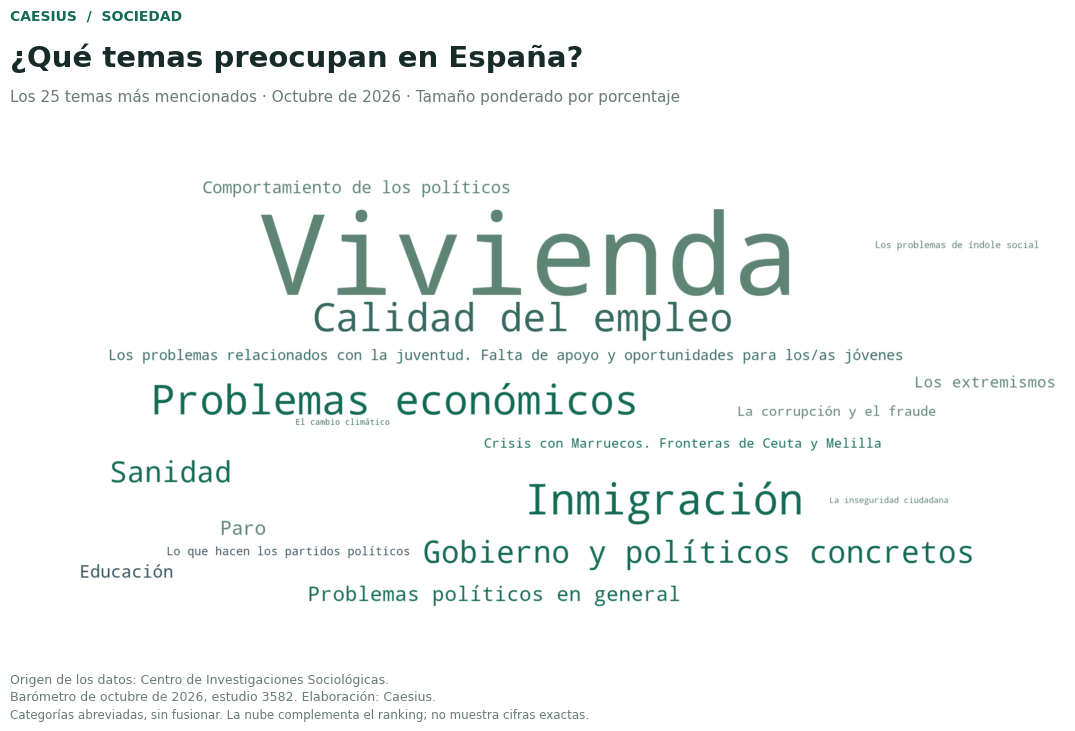

Guardados: 05-nube.png / .svg / .csv


1016

In [7]:
from wordcloud import WordCloud
# Selección explícita de 25 temas, sin repetir ni transformar los pesos.
seleccion_nube=pais.dropna().loc[lambda x:x>0].nlargest(25)
pesos={NOMBRES.get(p,p):float(v) for p,v in seleccion_nube.items()}
assert len(pesos)==len(seleccion_nube),"Dos etiquetas se solapan."
def color_nube(word,**kwargs):
    return [VERDE,"#376A60","#5D8474","#35515B"][sum(map(ord,word))%4]
nube=WordCloud(width=2000,height=950,background_color="white",random_state=42,
    prefer_horizontal=1,collocations=False,max_words=25,relative_scaling=1,
    min_font_size=16,margin=12,color_func=color_nube).generate_from_frequencies(pesos)
fig,ax=plt.subplots(figsize=(12,7.5))
fig.subplots_adjust(left=.035,right=.965,bottom=.15,top=.78)
ax.imshow(nube,interpolation="bilinear");ax.axis("off")
cabecera(fig,"¿Qué temas preocupan en España?","Los 25 temas más mencionados · Octubre de 2026 · Tamaño ponderado por porcentaje")
pie(fig,extra="Categorías abreviadas, sin fusionar. La nube complementa el ranking; no muestra cifras exactas.")
guardar(fig,"05-nube",seleccion_nube.rename("porcentaje").rename_axis("problema").reset_index())
# Formato de importación para WordArt: tema;peso, sin cabecera y con punto decimal.
(SALIDA/"05-nube-wordart.csv").write_text(
    "\n".join(f"{tema};{peso:.6f}" for tema,peso in pesos.items()),encoding="utf-8")

## Cifras del texto y trazabilidad
La celda siguiente permite comprobar los valores usados en el artículo y exporta el mapa entre etiquetas abreviadas y originales. Los enlaces de origen se refieren al CIS; los identificadores de estudio permiten localizar cada barómetro. No se inventan enlaces directos a estudios ni fechas de publicación.

La fecha de referencia de la encuesta **no es** la fecha de actualización del archivo. Los XLSX revisados no identifican de forma explícita una fecha de última actualización del documento; las propiedades técnicas de creación/modificación no se presentan como tal. Si una descarga futura incluye esa fecha, debe incorporarse a la cita y conservarse con los metadatos. Se mantienen los originales y las notas sin alterarlos.

In [8]:
comprobacion = {
    "vivienda_espana_octubre":float(pais[VIVIENDA]),
    "vivienda_personal_octubre":float(personal[VIVIENDA]),
    "cambio_vivienda_espana_septiembre_octubre_pp":float(serie.loc["2026-10","espana"]-serie.loc["2026-09","espana"]),
    "cambio_vivienda_personal_septiembre_octubre_pp":float(serie.loc["2026-10","personal"]-serie.loc["2026-09","personal"]),
}
display(pd.Series(comprobacion,name="valor").to_frame())
display(edad[edad.problema.isin(cuatro)].pivot(index="grupo",columns="problema",values="porcentaje").reindex(EDADES).round(2))
pd.DataFrame([{"problema_original":p,"etiqueta_grafica":NOMBRES.get(p,p)} for p in sorted(set(temas.problema))]).to_csv(
    SALIDA/"diccionario_etiquetas.csv",sep=";",index=False,encoding="utf-8-sig")
(SALIDA/"cifras_articulo.json").write_text(json.dumps(comprobacion,ensure_ascii=False,indent=2),encoding="utf-8")
# Guarda la procedencia por registro de los datos de octubre usados en los gráficos.
columnas = ["estudio","mes","tipo_problema","dimension","grupo","problema","porcentaje",
            "archivo","hoja","fila_excel","base_ponderada"]
temas[temas.mes.eq(MES)&temas.dimension.isin(["general","Edad"])][columnas].to_csv(
    SALIDA/"trazabilidad_octubre.csv",sep=";",decimal=",",index=False,encoding="utf-8-sig")
print("Exportación terminada. Los ficheros originales y datos_limpios se conservan sin cambios.")

,valor
vivienda_espana_octubre,55.650874
vivienda_personal_octubre,33.764330
cambio_vivienda_espana_septiembre_octubre_pp,18.179440
cambio_vivienda_personal_septiembre_octubre_pp,5.897576


problema,"La crisis económica, los problemas de índole económica",La sanidad,La vivienda,Los problemas relacionados con la calidad del empleo
grupo,,,,
De 18 a 24 años,32.59,12.09,65.02,21.95
De 25 a 34 años,38.67,18.16,60.23,30.47
De 35 a 44 años,41.78,25.46,37.28,25.10
De 45 a 54 años,35.05,24.69,28.00,21.06
De 55 a 64 años,28.37,26.25,28.63,16.87
De 65 a 74 años,20.99,28.29,21.50,10.34
75 y más años,13.32,27.14,13.95,7.23


Exportación terminada. Los ficheros originales y datos_limpios se conservan sin cambios.


## Fuente y criterios de análisis
**Origen de los datos: Centro de Investigaciones Sociológicas.** Tabulaciones XLSX de los barómetros de enero, febrero, marzo, abril, mayo, junio, julio, septiembre y octubre de 2026 (estudios 3540, 3544, 3546, 3557, 3562, 3567, 3571, 3577 y 3582). [Fuente original](https://www.cis.es/) · [Condiciones generales de reutilización](https://datos.gob.es/es/aviso-legal).

Se usa la columna de menciones totales, con los porcentajes ponderados tal como se publican. No se recalculan a partir de absolutos redondeados ni se ponderan por segunda vez. No se renombran categorías para fusionarlas: las abreviaturas son solo visuales. No sabe/no contesta, ninguno y otras respuestas conservan su peso en la base de cálculo aunque no aparezcan como temas. Ausencia de una categoría no equivale a cero; las notas mensuales de codificación pueden afectar a la comparabilidad. Antes de interpretar categorías poco frecuentes, consulta `notas_fuente.json` y `cobertura_categorias.csv`. No se suman porcentajes entre meses, grupos o categorías con posible solapamiento. Las diferencias son descriptivas y no pruebas de significación.

Elaboración y gráficos: Caesius. Las interpretaciones y el tratamiento estadístico son responsabilidad de Caesius. El CIS no participa, patrocina ni respalda esta reutilización. Conserva los XLSX, sus notas y metadatos de actualización y reutilización.